<a href="https://colab.research.google.com/github/nour2344/5ERPBI8_nourDhibi/blob/main/notebooks/02_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# RoadAnomaly — Data Preparation

This notebook prepares the RoadAnomaly images and segmentation masks for Deep Learning models.

## 1. Dataset Loading

Load the dataset from Google Drive and verify the correspondence between images and semantic masks.

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

dataset_dir = Path(
    "/content/drive/MyDrive/deep learning P/RoadAnomaly"
)

frames_dir = dataset_dir / "RoadAnomaly" / "frames"

print("Dataset exists:", dataset_dir.exists())
print("Frames exists:", frames_dir.exists())

Dataset exists: True
Frames exists: True


## 2. Image-Mask Pair Verification

Identify the original images and their corresponding semantic segmentation masks to ensure that all samples have valid annotations.

In [ ]:
import pandas as pd

images = sorted(frames_dir.glob("*.webp"))
pairs = []

for image_path in images:
    mask_path = (
        frames_dir
        / f"{image_path.stem}.labels"
        / "labels_semantic.png"
    )

    if mask_path.exists():
        pairs.append({
            "image": str(image_path),
            "mask": str(mask_path)
        })

df_pairs = pd.DataFrame(pairs)

print("Total images:", len(images))
print("Valid image-mask pairs:", len(df_pairs))

assert len(df_pairs) == len(images), "Missing masks detected!"

display(df_pairs.head())

Total images: 60
Valid image-mask pairs: 60


,image,mask
0,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
1,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
2,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
3,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...
4,/content/drive/MyDrive/deep learning P/RoadAno...,/content/drive/MyDrive/deep learning P/RoadAno...


### Why 70% / 15% / 15%?

- **70% Training:** Provides most images for learning anomaly patterns.
- **15% Validation:** Allows model selection and overfitting detection.
- **15% Testing:** Provides an independent final evaluation.


### Justification of the 70/15/15 Split

The **70/15/15 split** was selected to balance model learning, hyperparameter optimization, and independent evaluation, considering the limited size of the RoadAnomaly dataset (60 images).

- **70% Training (42 images):** Allocates the majority of the data to learning visual features and anomaly patterns.
- **15% Validation (9 images):** Enables hyperparameter tuning, model comparison, and early stopping without influencing the final test results.
- **15% Testing (9 images):** Preserves an independent subset for evaluating the generalization performance of the selected model.

**Why this choice?**

Unlike an 80/10/10 split, which would leave only 6 images for validation and 6 for testing, the 70/15/15 split provides slightly larger evaluation subsets while retaining most images for training.

**Limitation:** Given the small dataset, performance estimates may remain unstable. The split must also prevent images from the same source scene from appearing in different subsets.

In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd

def get_category(path):
    name = str(path).split("/")[-1].lower()

    for category in ["animals", "obstacles", "cones",
                     "vehicle", "lost_tires"]:
        if name.startswith(category):
            return category

    return "other"

df_pairs["category"] = df_pairs["image"].apply(get_category)

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df_pairs,
    test_size=0.30,
    random_state=42,
    stratify=df_pairs["category"]
)

# Second split: 15% validation, 15% testing
# No second stratification because some categories are small
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nCategory distribution:")
display(pd.DataFrame({
    "Train": train_df["category"].value_counts(),
    "Validation": val_df["category"].value_counts(),
    "Test": test_df["category"].value_counts()
}).fillna(0).astype(int))

Training images: 42
Validation images: 9
Testing images: 9

Category distribution:


,Train,Validation,Test
category,,,
animals,22,5,4
cones,6,0,2
lost_tires,2,0,1
obstacles,10,4,1
vehicle,2,0,1


In [ ]:
train_set = set(train_df["image"])
val_set = set(val_df["image"])
test_set = set(test_df["image"])

assert not train_set & val_set
assert not train_set & test_set
assert not val_set & test_set

assert len(train_set | val_set | test_set) == 60

print("No overlap between image filenames.")
print("Split created successfully!")

No overlap between image filenames.
Split created successfully!


## 4. Image Preprocessing

Prepare the road images and segmentation masks for Deep Learning.

### Methodological Choices

- **Resizing (256 × 256):** Reduces memory usage and computational cost, allowing faster training on Google Colab. However, it may affect the detection of small anomalies.
- **Normalization (0–1):** Scales image pixel values to a consistent range, facilitating neural network training.
- **Binary Mask Conversion (0/1):** Converts the original labels into two classes: non-anomalous pixels (0) and anomalous pixels (1).
- **Interpolation:** Bilinear interpolation for images and nearest-neighbor interpolation for masks to preserve discrete class labels.

**Note:** The original dataset remains unchanged.

In [ ]:
import numpy as np
from PIL import Image

IMG_SIZE = (256, 256)

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")

    # Resize image using bilinear interpolation
    image = image.resize(
        IMG_SIZE,
        Image.Resampling.BILINEAR
    )

    # Normalize pixel values to [0, 1]
    image = np.array(image, dtype=np.float32) / 255.0

    return image


def preprocess_mask(mask_path):
    mask = Image.open(mask_path)

    # Preserve class labels during resizing
    mask = mask.resize(
        IMG_SIZE,
        Image.Resampling.NEAREST
    )

    mask = np.array(mask)

    # Class 2 = anomaly, class 0 = non-anomaly
    binary_mask = (mask == 2).astype(np.uint8)

    return binary_mask


print("Preprocessing functions ready!")

Preprocessing functions ready!


### 4.1. Preprocessing Verification

Apply preprocessing to one image-mask pair and verify:

- Image dimensions: 256 × 256 × 3.
- Mask dimensions: 256 × 256.
- Image pixel values: between 0 and 1.
- Mask values: only 0 and 1.

Visualize the processed image and mask to ensure spatial correspondence is preserved.

Image shape: (256, 256, 3)
Mask shape: (256, 256)
Image range: 0.0 1.0
Mask unique values: [0 1]


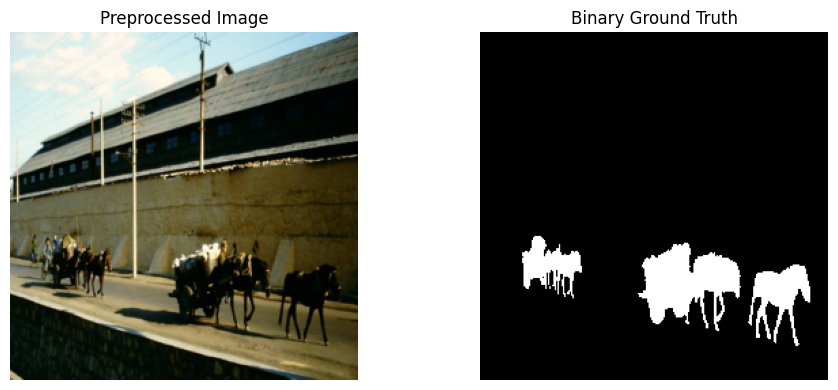

Preprocessing verification successful!


In [ ]:
import matplotlib.pyplot as plt

# Select one image-mask pair
sample = train_df.iloc[0]

image = preprocess_image(sample["image"])
mask = preprocess_mask(sample["mask"])

print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("Image range:", image.min(), image.max())
print("Mask unique values:", np.unique(mask))

# Verify preprocessing
assert image.shape == (256, 256, 3)
assert mask.shape == (256, 256)
assert image.min() >= 0 and image.max() <= 1
assert set(np.unique(mask)).issubset({0, 1})

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(image)
axes[0].set_title("Preprocessed Image")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Binary Ground Truth")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Preprocessing verification successful!")

## 5. Data Augmentation

Data augmentation generates random variations of training images to reduce overfitting and improve model generalization.

**Transformations:**
- Horizontal flipping: changes obstacle positions.
- Brightness and contrast adjustment: simulates different lighting conditions.

**Justification:** With only 42 training images, augmentation increases visual diversity without collecting new data.

**Important:** Augmentation is applied only to training images. Images and masks are flipped together to preserve annotation alignment.

In [ ]:
import numpy as np

rng = np.random.default_rng(42)

def augment_image_mask(image, mask, rng):
    image = image.copy()
    mask = mask.copy()

    # Random horizontal flip
    if rng.random() < 0.5:
        image = np.fliplr(image).copy()
        mask = np.fliplr(mask).copy()

    # Random brightness
    brightness = rng.uniform(0.8, 1.2)
    image = np.clip(image * brightness, 0, 1)

    # Random contrast
    contrast = rng.uniform(0.8, 1.2)
    mean = image.mean(axis=(0, 1), keepdims=True)
    image = np.clip((image - mean) * contrast + mean, 0, 1)

    return image.astype(np.float32), mask.astype(np.uint8)

print("Data augmentation ready!")

Data augmentation ready!


### 5.1. Augmentation Visualization

This cell is only for visualization.

It helps us understand how data augmentation creates different versions of the same training image.

We display:
- the original image,
- a horizontally flipped image,
- a brighter image,
- a darker image,
- a higher-contrast image.

**Note:** For road-scene anomaly detection, horizontal flipping is realistic, while vertical flipping or large rotations are not appropriate.

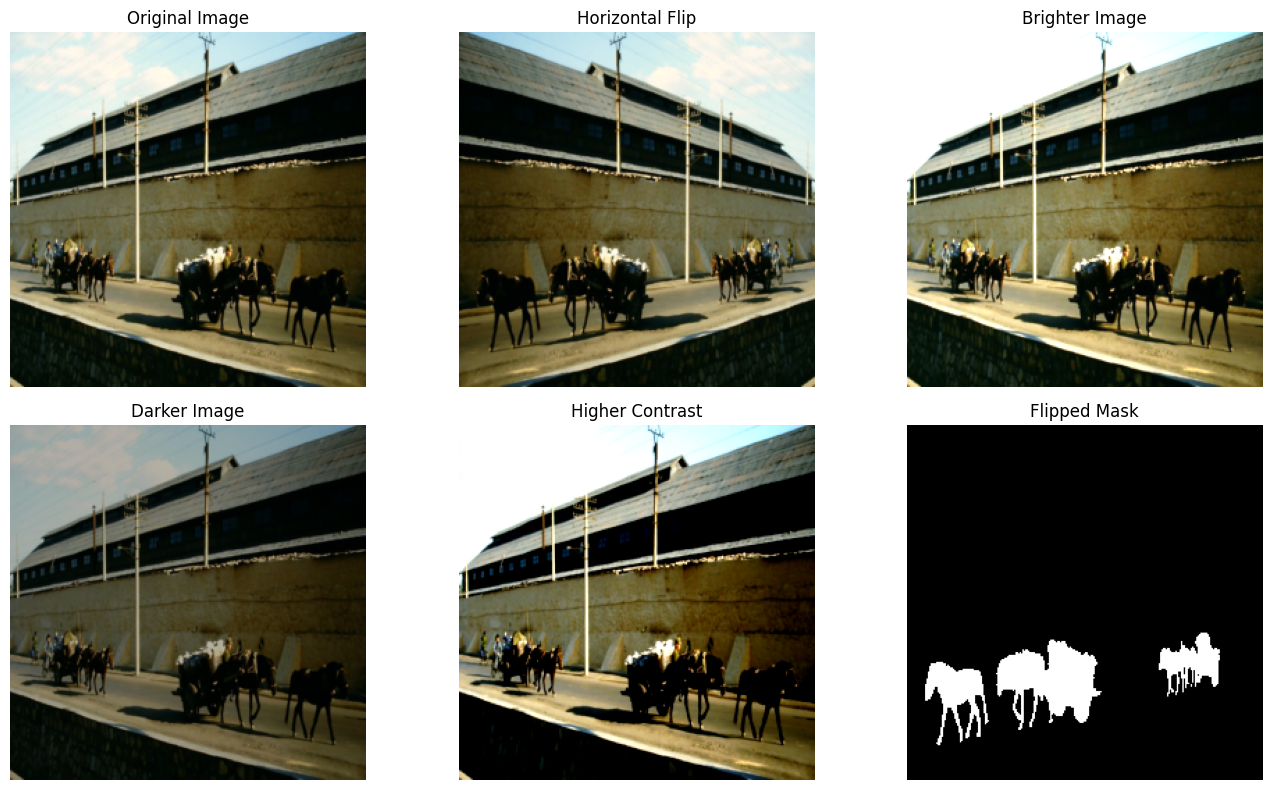

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Select one training example
sample = train_df.iloc[0]

image = preprocess_image(sample["image"])
mask = preprocess_mask(sample["mask"])

# Variants for visualization only
original = image.copy()
flipped = np.fliplr(image).copy()
flipped_mask = np.fliplr(mask).copy()

brighter = np.clip(image * 1.3, 0, 1)
darker = np.clip(image * 0.7, 0, 1)

mean = image.mean(axis=(0, 1), keepdims=True)
higher_contrast = np.clip((image - mean) * 1.4 + mean, 0, 1)

# Show image variants
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

axes[0, 0].imshow(original)
axes[0, 0].set_title("Original Image")

axes[0, 1].imshow(flipped)
axes[0, 1].set_title("Horizontal Flip")

axes[0, 2].imshow(brighter)
axes[0, 2].set_title("Brighter Image")

axes[1, 0].imshow(darker)
axes[1, 0].set_title("Darker Image")

axes[1, 1].imshow(higher_contrast)
axes[1, 1].set_title("Higher Contrast")

axes[1, 2].imshow(flipped_mask, cmap="gray", vmin=0, vmax=1)
axes[1, 2].set_title("Flipped Mask")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()